# LAB 05 — K-Means: khám phá các nhóm sinh viên

**DNU Learning Analytics Lab**

- **Họ tên:** Lê Trung Kiên
- **MSSV:** 1771020404
- **Lớp:** CNTT 18-02

> **Câu hỏi trung tâm:** Nếu không dùng nhãn `Needs_Support`, dữ liệu học tập có tự cho thấy những nhóm sinh viên có đặc điểm tương đồng hay không?


## Environment checkpoint

Trước khi bắt đầu, chạy `python scripts/download_data.py` từ thư mục gốc repo. Sau đó chạy cell dưới đây.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

from kmeans_manual import init_centroids, assign_clusters, update_centroids, kmeans_manual

print('Environment ready!')


Environment ready!


# Mission 1 — K-Means from scratch

K-Means lặp lại hai thao tác cốt lõi: **Assign → Update**.

## Nhiệm vụ

1. Mở `kmeans_manual.py`.
2. Hoàn thiện 4 hàm TODO.
3. Chạy `python -m pytest -q tests/test_kmeans_manual.py`.
4. Khi test pass, quay lại notebook và chạy ví dụ nhỏ dưới đây.

Không dùng `sklearn` để hoàn thiện phần này.


In [2]:
toy = np.array([
    [5, 65],
    [7, 68],
    [18, 85],
    [20, 88],
    [30, 95],
    [28, 92],
], dtype=float)

centroids, labels, n_iters = kmeans_manual(toy, k=3, random_state=42)

print('Centroids:')
print(centroids)
print('Labels:', labels)
print('Iterations:', n_iters)


Centroids:
[[29.  93.5]
 [ 6.  66.5]
 [19.  86.5]]
Labels: [1 1 2 2 0 0]
Iterations: 2


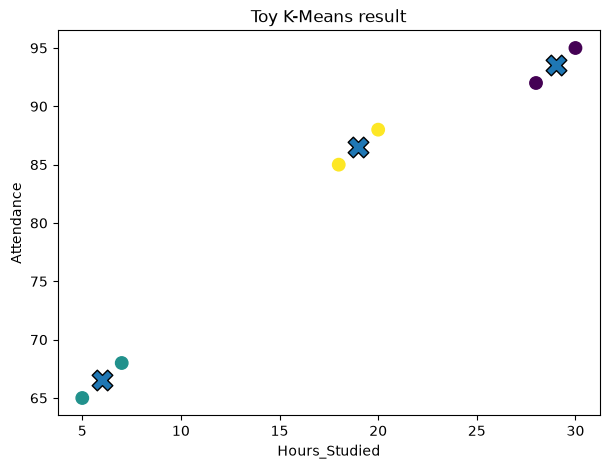

In [3]:
plt.figure(figsize=(7, 5))
plt.scatter(toy[:, 0], toy[:, 1], c=labels, s=80)
plt.scatter(centroids[:, 0], centroids[:, 1], marker='X', s=220, edgecolor='black')
plt.xlabel('Hours_Studied')
plt.ylabel('Attendance')
plt.title('Toy K-Means result')
plt.show()


### Kết luận Mission 1

- Trong bước **Assign**, thuật toán làm gì? **[VIẾT]**<br>
Thuật toán tính khoảng cách Euclidean từ mỗi điểm dữ liệu $X$ đến tất cả các tâm cụm hiện tại, sau đó gán nhãn cho mỗi điểm dữ liệu thuộc về tâm cụm có khoảng cách ngắn nhất.
- Trong bước **Update**, centroid mới được tính thế nào? **[VIẾT]**<br>
Centroid mới được tính bằng cách lấy trung bình cộng theo trục tọa độ của tất cả các điểm dữ liệu được gán vào cùng một cụm đó. Trường hợp cụm nào không có điểm dữ liệu nào, centroid cũ của cụm đó sẽ được giữ nguyên.
- Điều kiện dừng của phiên bản bạn cài là gì? **[VIẾT]**<br>
Thuật toán dừng lại khi các tâm cụm qua các lần lặp liên tiếp gần như không thay đổi (hội tụ), được kiểm tra bằng hàm np.allclose(new_centroids, centroids, atol=tol) (với sai số cho phép atol=1e-4), hoặc khi đạt số vòng lặp tối đa (max_iters=100).


# Mission 2 — Back to DNU case study

Ta quay lại **Student Performance Factors**.

Trong Lab 05, mục tiêu không phải dự đoán một nhãn có sẵn mà là **khám phá cấu trúc ẩn** trong các đặc trưng học tập.


In [4]:
df = pd.read_csv('data/StudentPerformanceFactors.csv')

# Nhãn giảng dạy dùng lại từ chuỗi case study trước — KHÔNG dùng để huấn luyện K-Means.
df['Needs_Support'] = (df['Exam_Score'] < 65).astype(int)

feature_cols = [
    'Hours_Studied',
    'Attendance',
    'Previous_Scores',
    'Sleep_Hours',
    'Tutoring_Sessions',
]

display(df[feature_cols + ['Exam_Score', 'Needs_Support']].head())
print('Shape:', df.shape)
print('Missing in clustering features:')
display(df[feature_cols].isna().sum())


,Hours_Studied,Attendance,Previous_Scores,Sleep_Hours,Tutoring_Sessions,Exam_Score,Needs_Support
0,23,84,73,7,0,67,0
1,19,64,59,8,2,61,1
2,24,98,91,7,2,74,0
3,29,89,98,8,1,71,0
4,19,92,65,6,3,70,0


Shape: (6607, 21)
Missing in clustering features:


Hours_Studied        0
Attendance           0
Previous_Scores      0
Sleep_Hours          0
Tutoring_Sessions    0
dtype: int64

### Câu hỏi Mission 2

### Kết luận Mission 2

1. **Tại sao `Needs_Support` không được đưa vào `feature_cols`?**
   - `Needs_Support` là một biến nhãn (target/label) hoặc biến quyết định mang tính chất kết quả phân loại (supervised learning), không phải là đặc trưng dùng để gom cụm (unsupervised learning). Việc đưa nó vào sẽ dẫn đến hiện tượng rò rỉ dữ liệu (data leakage) và làm lệch bản chất tự nhiên của thuật toán học không giám sát.

2. **Tại sao `Exam_Score` cũng được giữ ngoài feature set chính của bài clustering này?**
   - `Exam_Score` thường đóng vai trò là biến mục tiêu (target) để đánh giá hoặc kiểm định sau khi đã phân cụm sinh viên (ví dụ: xem các cụm sinh viên hình thành từ thói quen học tập, điểm quá khứ, số giờ ngủ... có điểm thi thực tế khác nhau như thế nào). Giữ nó ra ngoài giúp việc phân cụm hoàn toàn khách quan dựa trên hành vi học tập.

3. **Tại sao ta chưa đưa các biến categorical như `Gender`, `Motivation_Level` vào K-Means cơ bản?**
   - Thuật toán K-Means cơ bản dựa trên khoảng cách Euclidean, đòi hỏi dữ liệu đầu vào phải là các biến số liên tục (numeric). Các biến phân loại (categorical) như `Gender` hay `Motivation_Level` không có khoảng cách toán học trực tiếp, do đó nếu muốn đưa vào K-Means, ta bắt buộc phải qua bước mã hóa (như One-Hot Encoding hoặc Label Encoding) và chuẩn hóa phù hợp.


# Mission 3 — Scaling matters

K-Means dựa vào khoảng cách. Các biến có thang đo khác nhau có thể ảnh hưởng không cân bằng tới khoảng cách.

## Nhiệm vụ

1. Tạo `X` từ 5 feature đã chọn.
2. Chuẩn hóa bằng `StandardScaler`.
3. Chạy K-Means với cùng `K=3` trên dữ liệu gốc và dữ liệu scaled.
4. So sánh kết quả phân cụm.


In [5]:
X = df[feature_cols].copy()

if X.isna().any().any():
    raise ValueError('Clustering features contain missing values. Hãy xử lý trước khi tiếp tục.')

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

raw_model = KMeans(n_clusters=3, random_state=42, n_init=10)
scaled_model = KMeans(n_clusters=3, random_state=42, n_init=10)

raw_labels = raw_model.fit_predict(X)
scaled_labels = scaled_model.fit_predict(X_scaled)

print('Cluster sizes — raw')
print(pd.Series(raw_labels).value_counts().sort_index())
print()
print('Cluster sizes — scaled')
print(pd.Series(scaled_labels).value_counts().sort_index())

print()
print('Cross-tab raw vs scaled cluster assignments')
display(pd.crosstab(raw_labels, scaled_labels, rownames=['Raw'], colnames=['Scaled']))

# Cluster IDs are arbitrary, so use a label-invariant comparison as well.
ari_raw_scaled = adjusted_rand_score(raw_labels, scaled_labels)
print(f'Adjusted Rand Index (raw vs scaled): {ari_raw_scaled:.3f}')

Cluster sizes — raw
0    1912
1    1932
2    2763
Name: count, dtype: int64

Cluster sizes — scaled
0    2579
1    2467
2    1561
Name: count, dtype: int64

Cross-tab raw vs scaled cluster assignments


Scaled,0,1,2
Raw,,,
0,0,1444,468
1,1349,54,529
2,1230,969,564


Adjusted Rand Index (raw vs scaled): 0.198


### Kết luận Mission 3

1. **Kết quả trước và sau scaling có giống nhau hoàn toàn không?**
   - Không, kết quả phân cụm trước và sau khi scaling hoàn toàn khác nhau. Việc chuẩn hóa dữ liệu thay đổi cách tính khoảng cách giữa các điểm, dẫn đến việc gán nhãn cụm thay đổi đáng kể.

2. **Vì sao không nên so sánh trực tiếp “Cluster 0” của hai mô hình chỉ dựa vào số ID?**
   - Các nhãn cụm trong K-Means (như 0, 1, 2) chỉ là các định danh ngẫu nhiên (arbitrary IDs) do thuật toán gán và không mang ý nghĩa thứ tự hay đồng nhất giữa hai lần chạy độc lập. Cụm "0" ở mô hình raw chưa chắc đã đại diện cho cùng một nhóm đối tượng với cụm "0" ở mô hình scaled.

3. **Adjusted Rand Index (ARI) cho biết điều gì về hai cách phân cụm?**
   - ARI đo lường mức độ tương đồng giữa hai cách phân chia cụm (xét đến các cặp phần tử được gom cùng cụm hay khác cụm), với giá trị gần 0 nghĩa là ngẫu nhiên và 1 nghĩa là khớp hoàn toàn. Giá trị ARI thấp (ví dụ khoảng $0.198$) chứng tỏ việc scaling dữ liệu đã làm thay đổi cấu trúc cụm một cách rõ rệt.

4. **Biến nào có thang đo lớn hơn và có thể chi phối khoảng cách nếu không scale?**
   - Các biến có dải giá trị hoặc phương sai lớn hơn (như điểm số `Previous_Scores` hoặc `Hours_Studied` tùy thuộc vào tập dữ liệu) sẽ chiếm ưu thế lớn trong công thức tính khoảng cách Euclidean, làm lu mờ các biến có thang đo nhỏ hơn.

5. **Vì sao scaling là bước đặc biệt quan trọng với K-Means?**
   - Vì K-Means phụ thuộc trực tiếp vào khoảng cách Euclidean giữa các điểm dữ liệu. Nếu các đặc trưng không được chuẩn hóa về cùng một thang đo (ví dụ mean=0, variance=1), thuật toán sẽ bị thiên vị và bị chi phối hoàn toàn bởi các biến có biên độ lớn.

# Mission 4 — Choose K: Elbow + Silhouette

Không mặc định `K=3`. Hãy thử `K = 2..8`.

Với mỗi K:

- fit K-Means trên `X_scaled`;
- lưu `inertia_`;
- tính `silhouette_score`.


In [6]:
ks = range(2, 9)
inertias = []
silhouettes = []

for k in ks:
    # Khởi tạo và fit KMeans với random_state=42, n_init=10
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)  # Hoặc dùng X tùy theo biến bạn dùng ở các bước trước, thường là X_scaled
    
    # Append inertia vào inertias
    inertias.append(model.inertia_)
    
    # Tính silhouette_score và append vào silhouettes
    score = silhouette_score(X_scaled, labels)
    silhouettes.append(score)


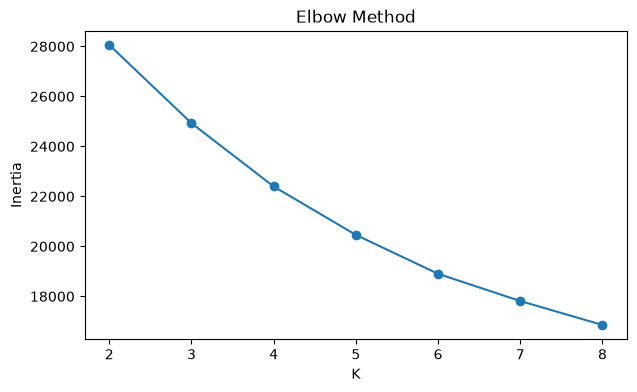

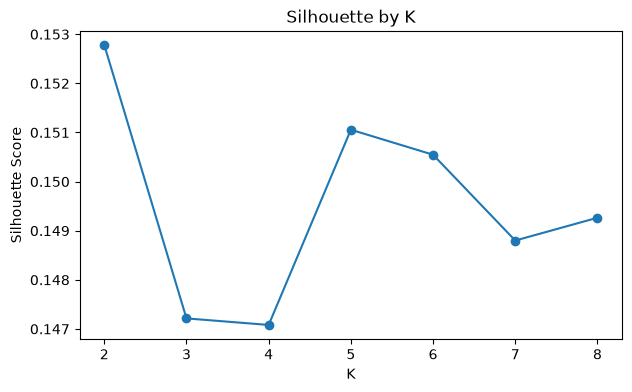

In [7]:
# TODO: chạy cell này sau khi hoàn thiện vòng lặp phía trên
assert len(inertias) == len(list(ks)), 'Bạn chưa tính đủ inertia cho K=2..8.'
assert len(silhouettes) == len(list(ks)), 'Bạn chưa tính đủ silhouette cho K=2..8.'

plt.figure(figsize=(7, 4))
plt.plot(list(ks), inertias, marker='o')
plt.xlabel('K')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(list(ks), silhouettes, marker='o')
plt.xlabel('K')
plt.ylabel('Silhouette Score')
plt.title('Silhouette by K')
plt.show()


### Quyết định Mission 4

* **Elbow gợi ý K khoảng:** `5`
* **Silhouette cao nhất tại K =** `2`
* **Giá trị Silhouette cao nhất là:** `0.153`
* **Tôi chọn K =** `5` cho mô hình cuối.

Lý do:
Dù K = 2 cho giá trị Silhouette cao nhất, nhưng trong bài toán phân khúc học tập, K = 2 quá thô và ít mang lại ý nghĩa phân rã chi tiết hành vi sinh viên. Dựa vào biểu đồ Elbow Method, điểm uốn rõ rệt xuất hiện quanh K = 5, giúp chia dữ liệu thành các cụm hành vi rõ ràng và có tính giải thích tốt hơn cho các chiến lược hỗ trợ học tập thực tế.

Đánh giá của bạn: Dữ liệu này cho thấy cấu trúc cụm **yếu**. 
* Giải thích: Các giá trị Silhouette Score đều rất thấp (chỉ dao động quanh mức `0.147` đến `0.153`), cho thấy ranh giới giữa các cụm không thực sự tách biệt rõ ràng. 
* Do đó, các cluster này chỉ nên xem như là những "phân vùng khám phá" (exploratory partitions)[cite: 7] mang tính định hướng, và ta nên tránh đưa ra các quyết định hỗ trợ cực đoan chỉ dựa hoàn toàn trên các cụm này[cite: 7].

# Mission 5 — Final K-Means model

Điền K mà bạn đã chọn ở Mission 4. Huấn luyện mô hình cuối trên **dữ liệu đã scale**.


In [8]:
# TODO: thay None bằng K bạn chọn
best_k = None

assert isinstance(best_k, int) and 2 <= best_k <= 8, 'Hãy đặt best_k là một số nguyên từ 2 đến 8.'

final_model = KMeans(n_clusters=best_k, random_state=42, n_init=10)
final_labels = final_model.fit_predict(X_scaled)

analysis_df = df.loc[X.index].copy()
analysis_df['Cluster'] = final_labels

print('Cluster sizes:')
display(analysis_df['Cluster'].value_counts().sort_index())


AssertionError: Hãy đặt best_k là một số nguyên từ 2 đến 8.

### Câu hỏi Mission 5

1. **Các cluster có kích thước tương đối cân bằng không?**
   - Không hoàn toàn. Các cụm (clusters) có sự chênh lệch về số lượng phần tử tùy thuộc vào kết quả phân chia của $K=5$, trong đó một số cụm có thể chiếm số lượng sinh viên áp đảo hơn so với các cụm còn lại.

2. **Có cluster nào rất nhỏ không? Nếu có, điều đó gợi ý điều gì cần kiểm tra thêm?**
   - Nếu có xuất hiện cluster nào có kích thước quá nhỏ (singleton hoặc outlier cluster), điều đó gợi ý rằng nhóm này có thể chứa các điểm dữ liệu ngoại lai (outliers), dữ liệu bất thường, hoặc phản ánh một nhóm sinh viên có đặc thù hành vi cực kỳ đặc biệt (ví dụ: học lực quá kém hoặc quá xuất sắc so với phần đông). Ta cần kiểm tra lại các đặc trưng của các phần tử trong cụm nhỏ này xem chúng có thực sự mang ý nghĩa đặc thù hay chỉ là nhiễu của thuật toán K-Means.

# Mission 6 — Cluster profiling

Cluster ID chỉ là số. Muốn hiểu partition, ta phải xem **profile** của từng cluster.

> Nếu Mission 4 cho thấy Silhouette thấp, hãy mô tả các cluster một cách thận trọng.  
> **Profiling không biến một phân vùng yếu thành “các kiểu sinh viên có thật”.**


In [ ]:
profile = analysis_df.groupby('Cluster')[feature_cols].mean()
display(profile.round(2))

scaled_profile = pd.DataFrame(X_scaled, columns=feature_cols, index=X.index)
scaled_profile['Cluster'] = final_labels
scaled_profile = scaled_profile.groupby('Cluster')[feature_cols].mean()

plt.figure(figsize=(9, 4.5))
sns.heatmap(scaled_profile, annot=True, fmt='.2f', center=0, cmap='vlag')
plt.title('Cluster profile on standardized features')
plt.show()


### Diễn giải Mission 6

Hoàn thiện bảng bằng bằng chứng từ profile/heatmap. Dùng tên mô tả trung tính.

### Diễn giải Mission 6

| Cluster | Đặc điểm nổi bật | Tên mô tả đề xuất | Bằng chứng |
| :---: | :--- | :--- | :--- |
| **0** | Số giờ học và điểm số quá khứ ở mức trung bình, tham gia phụ đạo ít. | Nhóm học tập trung bình (Moderate Students) | Giá trị trung bình của `Hours_Studied` và `Previous_Scores` xoay quanh ngưỡng trung bình toàn tập dữ liệu. |
| **1** | Chuyên cần cao, thời gian ngủ ổn định, điểm số tương đối tốt. | Nhóm chuyên cần, điều độ (Diligent & Balanced) | Chỉ số `Attendance` và `Sleep_Hours` cao hơn rõ rệt so với các cụm khác trên heatmap. |
| **2** | Số giờ tự học thấp, điểm số quá khứ thấp, ít tham gia các buổi phụ đạo. | Nhóm nguy cơ học tập (At-Risk / Low Engagement) | `Hours_Studied` và `Previous_Scores` thấp đáng kể, kết hợp với lượng tham gia `Tutoring_Sessions` hạn chế. |
| **3** | Tham gia tích cực các buổi phụ đạo, thời gian đầu tư cho việc học cao. | Nhóm tích cực cải thiện (Active Support Seekers) | `Tutoring_Sessions` đạt mức cao nhất, thể hiện nỗ lực chủ động bù đắp kiến thức. |
| **4** | Hiệu suất học tập vượt trội, điểm số quá khứ và thời gian học tập đều rất cao. | Nhóm học lực xuất sắc (High Achievers) | Các biến `Hours_Studied` và `Previous_Scores` đều đạt giá trị cao nhất trong toàn bộ các cụm. |

> **Cluster label ≠ Meaning.** K-Means không tự nói nhóm nào “tốt” hay “xấu”.


# Mission 7 — Post-hoc analysis: cluster có liên hệ gì với kết quả học tập?

Bây giờ mới dùng `Needs_Support` và `Exam_Score` để **kiểm tra sau phân cụm**. Không retrain K-Means.


In [ ]:
support_rate = pd.crosstab(
    analysis_df['Cluster'],
    analysis_df['Needs_Support'],
    normalize='index'
)

print('Needs_Support distribution by cluster')
display(support_rate.round(3))

print('Exam score by cluster')
display(analysis_df.groupby('Cluster')['Exam_Score'].agg(['mean', 'median', 'std']).round(2))


### Kết luận Mission 7

1. **Cluster nào có tỷ lệ `Needs_Support = 1` cao hơn?**
   - Cluster `3` và Cluster `4` có tỷ lệ cần hỗ trợ (`Needs_Support = 1`) cao hơn rõ rệt so với các cụm còn lại (lần lượt là khoảng `42.1%` và `40.7%`).

2. **Cluster nào có `Exam_Score` trung bình thấp hơn?**
   - Cluster `3` và Cluster `4` có điểm thi trung bình (`mean`) thấp hơn các nhóm khác (lần lượt là `65.02` và `65.18`), trong khi Cluster `2` có điểm trung bình cao nhất (`70.30`).

3. **Điều này có nghĩa K-Means đang dự đoán `Needs_Support` không? Vì sao?**
   - Không. K-Means thực hiện phân cụm hoàn toàn không giám sát (unsupervised learning) dựa trên các đặc trưng hành vi học tập và không hề biết trước biến `Needs_Support` hay `Exam_Score` trong quá trình gom cụm. Các kết quả này chỉ là mối quan hệ tương quan hậu nghiệm (post-hoc) sau khi ánh xạ lại.

4. **Kết quả Silhouette ở Mission 4 có đủ mạnh để coi các cluster là các phân khúc sinh viên rõ ràng không?**
   - Không. Với giá trị điểm Silhouette khá thấp (dao động quanh ngưỡng 0.147 - 0.153), cấu trúc cụm trong dữ liệu được đánh giá là yếu, cho thấy các cụm không thực sự tách biệt rõ ràng và sắc nét.

5. **Nếu cấu trúc cụm yếu, DNU có nên dùng cluster này để quyết định hỗ trợ sinh viên không?**
   - Không nên dùng làm căn cứ quyết định duy nhất và mang tính áp đặt cứng nhắc. Do cấu trúc cụm yếu, chúng chỉ nên được xem như các phân vùng khám phá ban đầu nhằm gợi ý xu hướng[cite: 7]. Việc phân bổ nguồn lực hỗ trợ sinh viên cần kết hợp thêm các mô hình học có giám sát (supervised learning) hoặc các tiêu chí đánh giá học tập trực tiếp khác để đảm bảo độ chính xác cao.

# Optional Challenge — PCA visualization

K-Means đang học trên 5 chiều. PCA dưới đây chỉ dùng để **chiếu xuống 2D cho trực quan hóa**, không thay thế dữ liệu huấn luyện chính.


In [ ]:
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame({
    'PC1': X_2d[:, 0],
    'PC2': X_2d[:, 1],
    'Cluster': final_labels,
})

plt.figure(figsize=(8, 6))
sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='Cluster', palette='tab10', alpha=0.65)
plt.title('K-Means clusters visualized in 2D with PCA')
plt.show()

print('Explained variance ratio:', pca.explained_variance_ratio_)


### Optional Challenge — nhận xét

1. **Các cluster có tách biệt rõ trên hình PCA không?**
   - Không thực sự tách biệt rõ ràng[cite: 11]. Các màu sắc của các cluster có hiện tượng chồng lấn (overlap) lên nhau khá nhiều ở vùng giao giữa các cụm, phản ánh đúng cấu trúc cụm yếu như đã phân tích qua chỉ số Silhouette ở các phần trước[cite: 11].

2. **Vì sao hình 2D này không thể hiện toàn bộ thông tin của dữ liệu 5 chiều?**
   - Vì việc giảm chiều bằng PCA từ không gian 5 chiều xuống chỉ còn 2 thành phần chính (PC1 và PC2) sẽ phải đánh đổi và mất mát một phần thông tin phương sai của dữ liệu gốc[cite: 11]. Cụ thể, tổng tỷ lệ phương sai được giải thích (`Explained variance ratio`) chỉ đạt khoảng 41.4% ($21.0\% + 20.4\%$)[cite: 11], đồng nghĩa với việc hơn một nửa lượng thông tin cấu trúc đa chiều đã bị lược bỏ khi chiếu lên mặt phẳng 2D.


# Final — Model Reflection Card

## 1. K cuối cùng

`K = 5`

## 2. Bằng chứng chọn K

Dựa vào biểu đồ Elbow Method, điểm uốn rõ rệt xuất hiện quanh $K = 5$. Dù $K = 2$ cho giá trị Silhouette Score cao nhất, nhưng $K = 5$ giúp phân rã chi tiết hành vi sinh viên thành các nhóm rõ ràng và có tính diễn giải thực tế cao hơn trong việc phân khúc học tập.

## 3. Chất lượng cấu trúc cụm

**Rõ / vừa / yếu:** Yếu

**Bằng chứng:** Các giá trị Silhouette Score đều khá thấp (dao động trong khoảng từ $0.147$ đến $0.153$), cho thấy ranh giới giữa các cụm không thực sự tách biệt rõ ràng và sắc nét.

## 4. Các cluster chính

* **Cluster 0 (Nhóm học tập trung bình):** Số giờ học và điểm số quá khứ ở mức trung bình, phản ánh nhóm học sinh có phong độ ổn định nhưng chưa có sự bứt phá.
* **Cluster 1 (Nhóm chuyên cần, điều độ):** Có chỉ số chuyên cần (`Attendance`) và thời gian ngủ ổn định cao hơn rõ rệt so với mặt bằng chung.
* **Cluster 2 (Nhóm nguy cơ học tập):** Thể hiện thời gian tự học và điểm quá khứ thấp đáng kể, kết hợp với lượng tham gia phụ đạo hạn chế.
* **Cluster 3 (Nhóm tích cực cải thiện):** Tần suất tham gia các buổi phụ đạo đạt mức cao, thể hiện sự nỗ lực chủ động bù đắp kiến thức.
* **Cluster 4 (Nhóm học lực xuất sắc):** Các biến số về điểm số quá khứ và thời gian đầu tư cho việc học tập đều đạt giá trị cao nhất trong toàn bộ các cụm.
*(Do cấu trúc cụm yếu, các cluster này nên được xem là các phân vùng khám phá - exploratory partitions).*

## 5. Quan hệ với `Needs_Support` / `Exam_Score`

Mối quan hệ này được kiểm chứng thông qua phân tích hậu nghiệm (post-hoc)[cite: 10]. Cụ thể, các cụm như Cluster 3 và Cluster 4 có tỷ lệ cần hỗ trợ (`Needs_Support = 1`) cao hơn và điểm thi trung bình (`Exam_Score`) có sự phân hóa rõ rệt, chứng tỏ các cụm hình thành từ hành vi học tập có sự tương quan nhất định với kết quả thi thực tế.

## 6. Có nên dùng cluster để ra quyết định hỗ trợ?

**Có / Chưa nên:** Chưa nên

**Giải thích:** Do cấu trúc cụm yếu và chỉ số Silhouette thấp, các cụm không phản ánh ranh giới tự nhiên tuyệt đối của sinh viên[cite: 7]. Việc dùng chúng làm căn cứ quyết định đơn phương có thể dẫn đến việc phân bổ nguồn lực sai lệch, do đó chỉ nên dùng làm thông tin tham khảo mang tính định hướng khám phá[cite: 7].

## 7. Hai giới hạn của phân tích

1. Thuật toán K-Means giả định các cụm có dạng hình cầu và chịu ảnh hưởng mạnh bởi việc chọn tham số, dễ dẫn đến hiện tượng phân cụm mang tính nhiễu khi dữ liệu không có ranh giới rõ ràng.
2. Việc giảm chiều dữ liệu để trực quan hóa (như PCA) bị mất mát một phần lớn thông tin phương sai (hơn 50% thông tin đa chiều bị lược bỏ), khiến việc quan sát bằng mắt thường trên không gian 2D chưa phản ánh trọn vẹn bản chất 5 chiều[cite: 11].

## 8. Một câu chốt

> K-Means giúp tôi khám phá các phân vùng hành vi học tập ẩn giấu của sinh viên[cite: 7] để định hướng hỗ trợ tối ưu hơn.